# 01 - Análise exploratória (EDA) — Etapa 1: geração hidráulica e GSF

**Objetivo:** entender o que determina o GH_band (geração hidráulica do MRE usada no GSF da bandeira), usando as
variáveis **previstas pelo ONS no PMO** de cada mês (DECOMP rv0), o mesmo conjunto de informação que gera o GH_band.

**Dados:** jan–out/2026 — `sumario.rv0`, `renovaveis.csv` e `ena.pdf` (ONS), boletins InfoBandeira (CCEE) e patamares (CCEE).
Memorial de cálculo em `docs/metodologia.md`, seção 3.5. **Limite:** só 10 meses de um único ano.

In [1]:
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import features, graficos, load

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Base mensal

Monta a base a partir dos arquivos brutos e salva em `data/processed/base_mensal_2026.parquet`.

In [2]:
base = features.base_mensal(2026)
base.to_parquet(load.DATA_PROCESSED / "base_mensal_2026.parquet")
base.shape

(10, 41)

## 2. Validação do alvo contra os boletins

GH_band e GSF calculados a partir do `sumario.rv0` contra os valores publicados pela CCEE; cor pela regra (ábaco) com o
GSF e o PLD gatilho do boletim. O PLD gatilho vem do deck da CCEE, **não** do CMO do ONS.

In [3]:
from forecast_bandeiras import regra

val = base[["gh_band", "gh_band_boletim", "gf_band_boletim", "gsf_calc", "gsf_band_boletim",
            "pld_gatilho_boletim", "cor_boletim"]].copy()
val["dif_gh_band"] = val.gh_band - val.gh_band_boletim
val["cor_regra"] = [regra.cor_bandeira(g, p) for g, p in zip(val.gsf_band_boletim, val.pld_gatilho_boletim)]
val

,gh_band,gh_band_boletim,gf_band_boletim,gsf_calc,gsf_band_boletim,pld_gatilho_boletim,cor_boletim,dif_gh_band,cor_regra
mes,,,,,,,,,
2026-01-01,"50,468.10","50,469.00","52,985.00",0.95,0.95,183.05,Verde,-0.90,Verde
2026-02-01,"53,196.40","53,196.00","52,965.00",1.00,1.00,354.65,Verde,0.40,Verde
2026-03-01,"54,396.96","54,397.00","52,859.00",1.03,1.03,427.08,Verde,-0.04,Verde
2026-04-01,"51,384.10","51,385.00","52,806.00",0.97,0.97,258.01,Verde,-0.90,Verde
2026-05-01,"42,280.27","42,280.00","52,851.00",0.80,0.80,237.58,Amarela,0.27,Amarela
2026-06-01,"37,478.81","37,478.00","52,888.00",0.71,0.71,222.92,Amarela,0.81,Amarela
2026-07-01,"37,226.08","37,226.00","52,899.00",0.70,0.70,171.48,Amarela,0.08,Amarela
2026-08-01,"37,884.66","37,885.00","52,911.00",0.72,0.72,128.67,Amarela,-0.34,Amarela
2026-09-01,"40,250.20","40,251.00","52,869.00",0.76,0.76,163.44,Amarela,-0.80,Amarela


## 3. Fechamento do balanço

`carga líquida + bombeamento = hidráulica (SIN) + eólica + solar + térmica + PCH + PCT`. O resíduo de ~−50 a −76 MWmed é o
**consumo de bombeamento** (usinas elevatórias), que só aparece no `relato.rv0` (por ora, só out/2026): com ele o balanço
de out/2026 fecha em −0,08 MWmed.

In [4]:
balanco = base[["carga_bruta", "mmgd", "carga_liquida", "gh_sin", "eol", "ufv", "termica", "nuclear",
                 "pch", "pct", "residuo", "bombeamento"]]
balanco.assign(residuo_pct=100 * balanco.residuo / balanco.carga_liquida)

,carga_bruta,mmgd,carga_liquida,gh_sin,eol,ufv,termica,nuclear,pch,pct,residuo,bombeamento,residuo_pct
mes,,,,,,,,,,,,,
2026-01-01,"84,395.70","7,410.97","76,984.72","49,643.71","10,250.33","4,764.96","6,575.68","1,293.18","3,913.39","1,910.47",-73.82,73.83,-0.10
2026-02-01,"87,601.81","7,731.91","79,869.90","52,347.63","9,988.71","4,811.78","6,745.01",640.00,"4,094.93","1,932.56",-50.73,50.66,-0.06
2026-03-01,"87,568.02","7,572.36","79,995.66","53,904.46","7,819.22","4,965.12","7,043.42","1,253.37","4,074.22","2,244.62",-55.42,55.49,-0.07
2026-04-01,"84,122.21","7,582.30","76,539.92","50,986.06","5,663.96","4,750.56","7,681.83","1,814.89","3,742.70","3,766.31",-51.50,51.44,-0.07
2026-05-01,"80,553.26","7,136.44","73,416.82","41,871.81","13,736.95","4,160.99","5,408.38","1,990.00","3,207.15","5,107.62",-76.08,76.11,-0.10
2026-06-01,"78,193.38","7,171.30","71,022.09","36,864.60","13,789.35","3,969.09","8,004.86","1,990.00","3,240.21","5,199.00",-45.04,44.98,-0.06
2026-07-01,"77,820.11","7,522.63","70,297.48","36,824.24","13,297.31","4,126.53","7,670.79","1,990.00","2,890.26","5,534.93",-46.58,46.59,-0.07
2026-08-01,"81,291.11","9,103.80","72,187.31","37,748.72","14,801.10","4,387.34","7,372.18","1,990.00","2,511.23","5,416.70",-49.95,50.00,-0.07
2026-09-01,"85,273.35","8,933.35","76,340.00","40,161.15","15,410.61","4,755.03","8,191.84","1,734.00","2,580.79","5,292.36",-51.77,51.71,-0.07


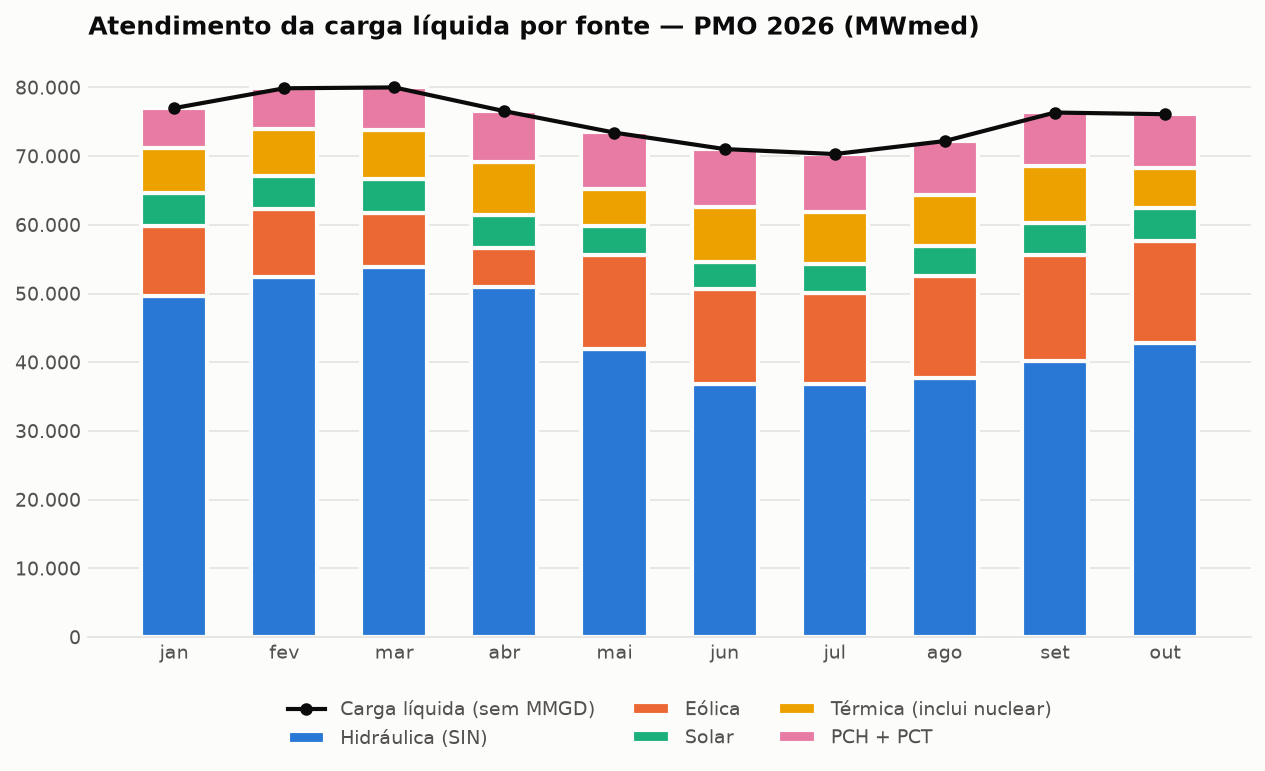

In [5]:
display(Image(graficos.balanco_empilhado(base)))

## 4. A hidráulica acompanha a carga residual

**Carga residual** = carga líquida − eólica − solar − PCH − PCT − nuclear: o que sobra para hidráulica + térmica não nuclear
depois das fontes que são, em princípio, dadas (projetáveis sem depender da hidrologia).

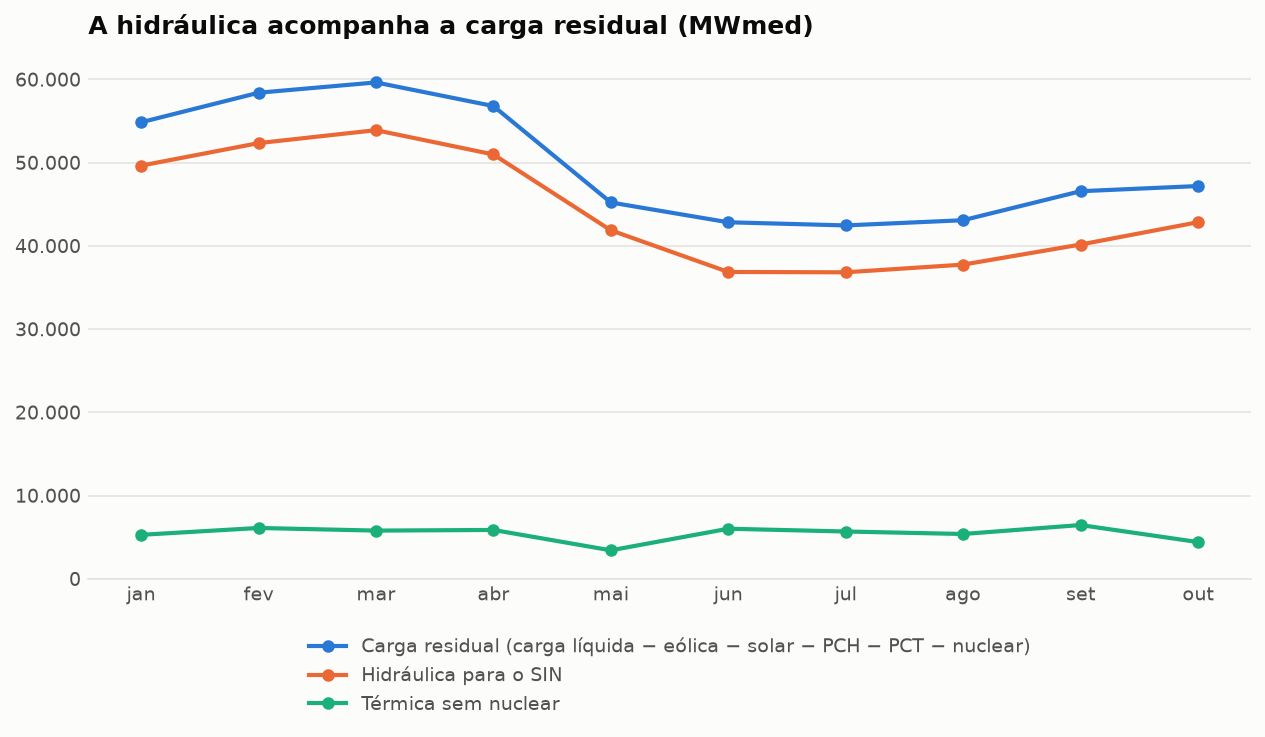

In [6]:
display(Image(graficos.gh_vs_carga_residual(base)))

## 5. GH_band contra as variáveis candidatas

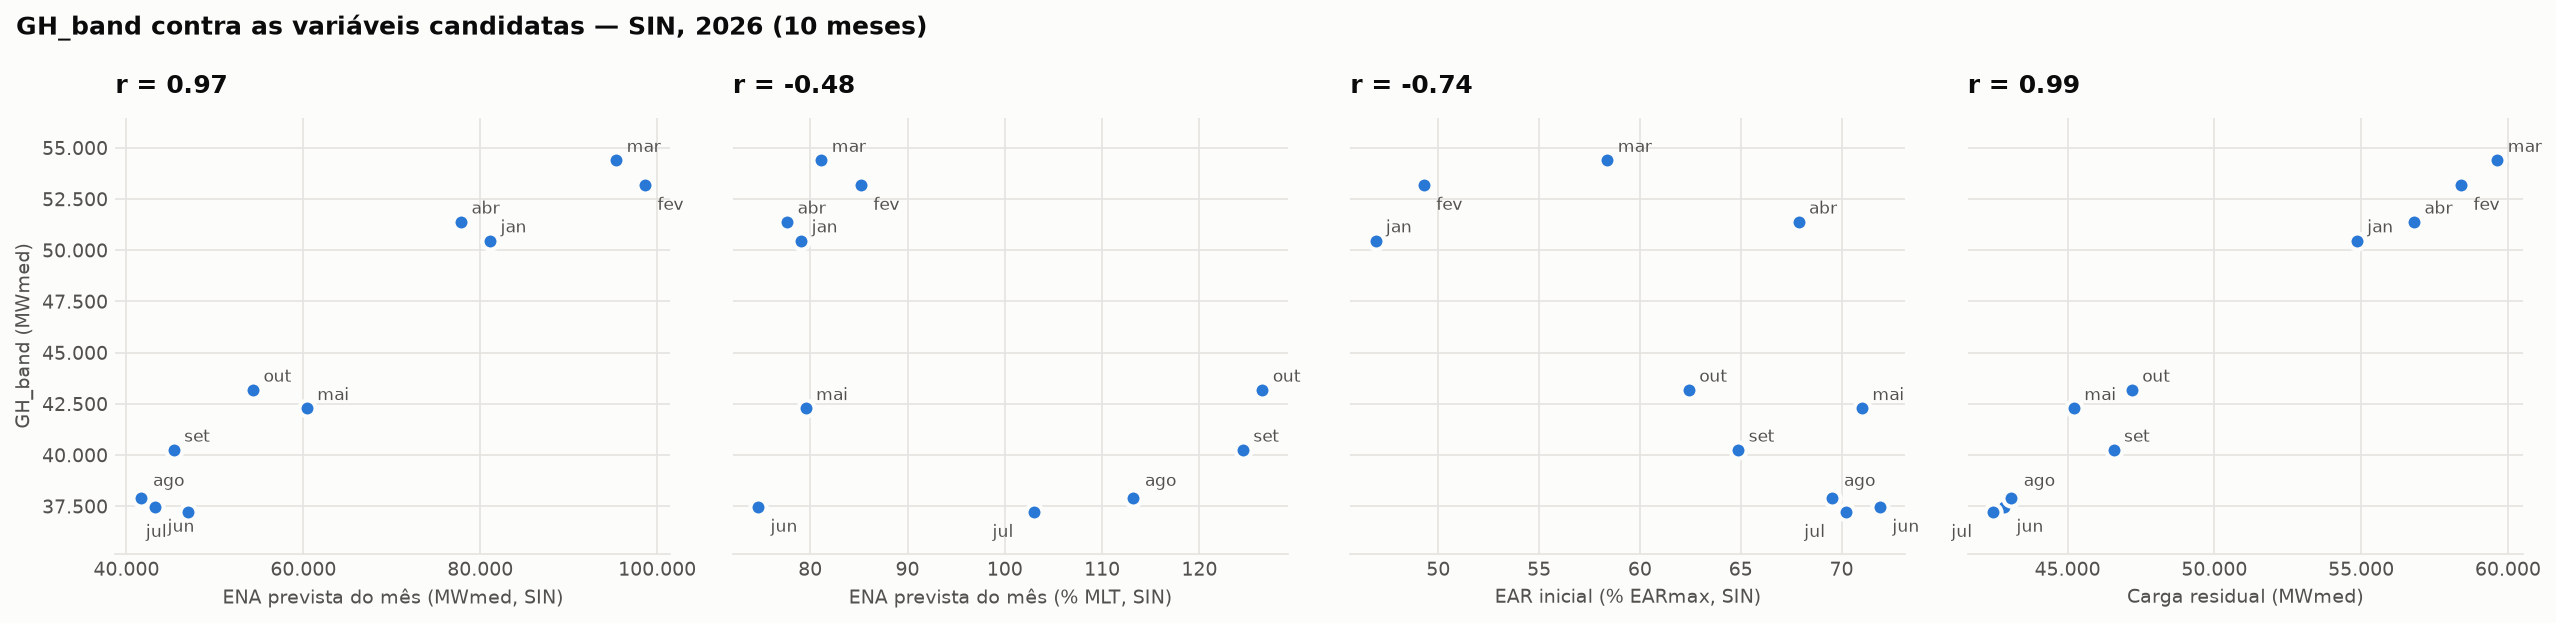

In [7]:
display(Image(graficos.dispersoes_gh(base)))

In [8]:
cols = ["carga_residual", "carga_liquida", "eol", "ufv", "pch", "pct", "termica_sem_nuclear",
        "ena_sin", "ena_mlt_sin", "ear_ini_sin"]
base[cols + ["gh_band"]].corr()["gh_band"].drop("gh_band").sort_values().to_frame("correlação com GH_band")

,correlação com GH_band
pct,-0.93
eol,-0.85
ear_ini_sin,-0.74
ena_mlt_sin,-0.48
termica_sem_nuclear,0.13
ufv,0.76
carga_liquida,0.90
pch,0.91
ena_sin,0.97
carga_residual,0.99


## 6. ENA × geração hidráulica (SIN)

A ENA entra de duas formas: em MWmed (volume de água, fortemente sazonal) e em % da MLT (quanto acima ou abaixo da média
histórica do mês, sem a sazonalidade).

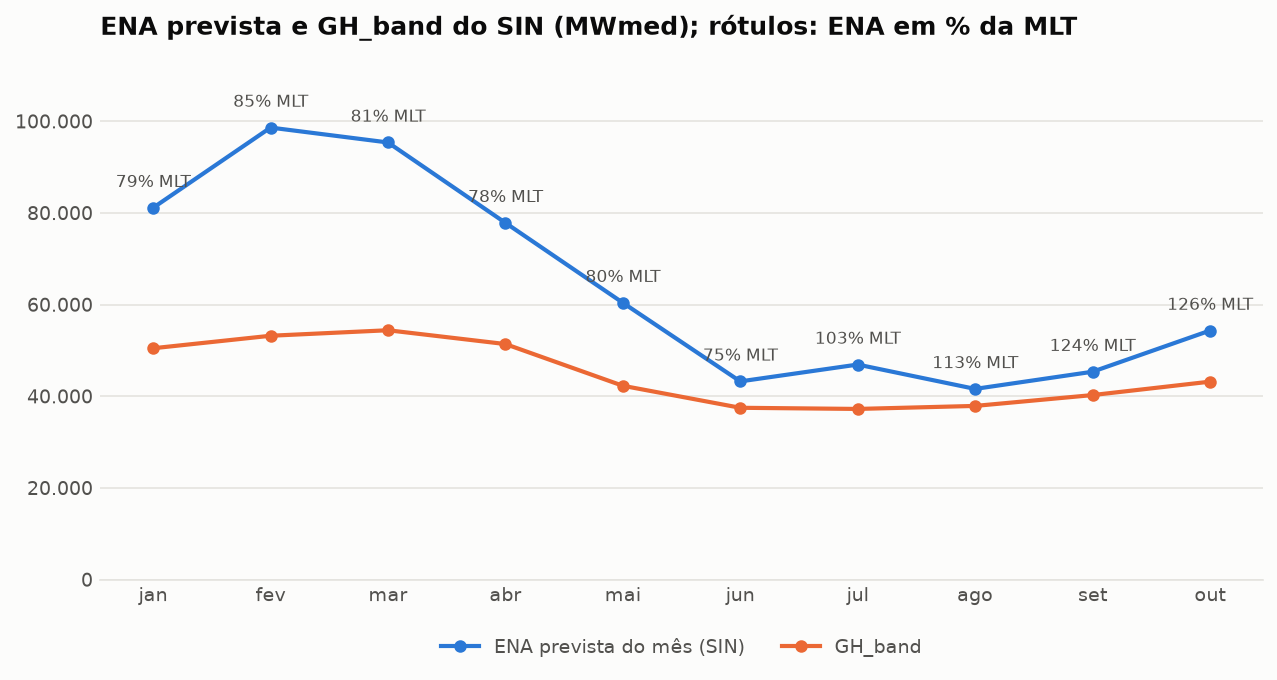

In [9]:
display(Image(graficos.gh_vs_ena(base)))

In [10]:
ena = pd.DataFrame({
    "corr. com GH_band": base[["ena_sin", "ena_mlt_sin", "ear_ini_sin", "carga_residual"]].corrwith(base.gh_band),
    "corr. com carga residual": base[["ena_sin", "ena_mlt_sin", "ear_ini_sin", "carga_residual"]].corrwith(base.carga_residual),
})
ena

,corr. com GH_band,corr. com carga residual
ena_sin,0.97,0.96
ena_mlt_sin,-0.48,-0.45
ear_ini_sin,-0.74,-0.73
carga_residual,0.99,1.00


A ENA em MWmed e a carga residual andam juntas (mesma sazonalidade: período úmido = muita água, pouco vento, carga alta).
Para separar os efeitos, tiramos do GH_band a parte explicada pela carga residual e vemos se o que sobra acompanha a ENA.

GH_band ≈ 0.986 × carga residual -4,216  |  desvio do resíduo: 926 MWmed


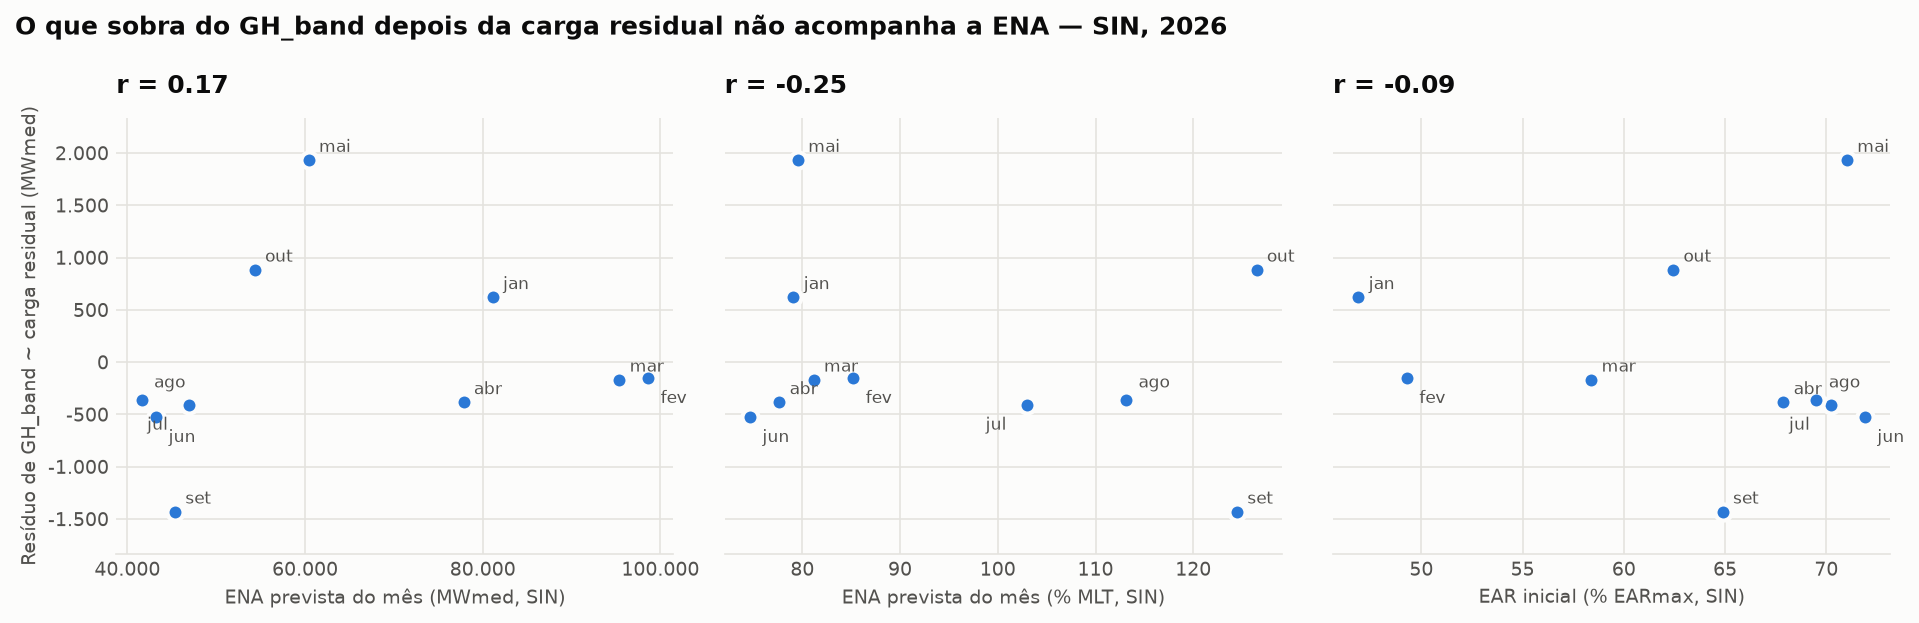

,resíduo,térmica sem nuclear,ENA % MLT,EAR inicial
mes,,,,
2026-01-01,619.26,"5,282.50",79.08,46.89
2026-02-01,-151.00,"6,105.01",85.21,49.28
2026-03-01,-169.86,"5,790.06",81.15,58.39
2026-04-01,-385.87,"5,866.94",77.64,67.87
2026-05-01,"1,931.34","3,418.38",79.54,71.01
2026-06-01,-524.61,"6,014.86",74.64,71.90
2026-07-01,-406.77,"5,680.79",103.02,70.22
2026-08-01,-361.75,"5,382.18",113.12,69.51
2026-09-01,"-1,432.41","6,457.84",124.46,64.88


In [11]:
import numpy as np

coef = np.polyfit(base.carga_residual, base.gh_band, 1)
residuo_gh = base.gh_band - np.polyval(coef, base.carga_residual)
print(f"GH_band ≈ {coef[0]:.3f} × carga residual {coef[1]:+,.0f}  |  desvio do resíduo: {residuo_gh.std():,.0f} MWmed")
display(Image(graficos.residuo_vs_ena(base, residuo_gh)))
pd.DataFrame({"resíduo": residuo_gh, "térmica sem nuclear": base.termica_sem_nuclear,
              "ENA % MLT": base.ena_mlt_sin, "EAR inicial": base.ear_ini_sin})

## 7. Térmica: inflexível × mérito (`relato.rv0`)

No `relato.rv0`, cada usina traz a geração por patamar com flag `I` (no mínimo, GTmin) ou `S` (no máximo, GTmax).
Parcela inflexível = min(geração, GTmin) por usina; o restante é mérito.

In [12]:
ter = base[["termica", "nuclear", "termica_inflexivel_sem_nuclear", "termica_merito", "ena_mlt_sin", "ear_ini_sin"]].copy()
ter["merito_pct"] = 100 * ter.termica_merito / ter.termica
ter

,termica,nuclear,termica_inflexivel_sem_nuclear,termica_merito,ena_mlt_sin,ear_ini_sin,merito_pct
mes,,,,,,,
2026-01-01,"6,575.68","1,293.18","2,254.74","3,027.76",79.08,46.89,46.04
2026-02-01,"6,745.01",640.00,"2,400.76","3,704.26",85.21,49.28,54.92
2026-03-01,"7,043.42","1,253.37","2,476.86","3,313.20",81.15,58.39,47.04
2026-04-01,"7,681.83","1,814.89","2,088.56","3,778.37",77.64,67.87,49.19
2026-05-01,"5,408.38","1,990.00","1,582.93","1,835.45",79.54,71.01,33.94
2026-06-01,"8,004.86","1,990.00","2,688.62","3,326.25",74.64,71.90,41.55
2026-07-01,"7,670.79","1,990.00","3,866.39","1,814.40",103.02,70.22,23.65
2026-08-01,"7,372.18","1,990.00","4,266.39","1,115.79",113.12,69.51,15.14
2026-09-01,"8,191.84","1,734.00","5,155.22","1,302.61",124.46,64.88,15.90


In [13]:
pd.DataFrame({
    "corr. com ENA % MLT": base[["termica_sem_nuclear", "termica_merito", "termica_inflexivel_sem_nuclear"]].corrwith(base.ena_mlt_sin),
    "corr. com o resíduo de GH": base[["termica_sem_nuclear", "termica_merito", "termica_inflexivel_sem_nuclear"]].corrwith(residuo_gh),
})

,corr. com ENA % MLT,corr. com o resíduo de GH
termica_sem_nuclear,0.01,-0.94
termica_merito,-0.87,-0.15
termica_inflexivel_sem_nuclear,0.91,-0.58


A térmica por mérito caiu no 2º semestre (de 3,0–3,8 mil para 0,5–1,8 mil MWmed), acompanhando a ENA acima da média
(r = −0,87 com a ENA em % MLT): carvão do NE (Pecém, Itaqui) e gás (Maranhão IV/V, Baixada Fluminense) saíram do despacho.
Ao mesmo tempo, a térmica inflexível subiu (de 2,3 para 5,2 mil): GNL com despacho definido antecipadamente (UTE GNA II,
Barcarena) e carvão do Sul (Candiota, Jorge Lacerda, Pampa Sul). Uma compensou a outra, e o que importa para a hidráulica
é a **térmica total sem nuclear** (r = −0,94 com o resíduo de GH).

## 8. Por que a hidráulica cai no período seco?

Variação média entre o período úmido (jan–abr) e o seco (jun–set). Pela identidade do balanço,
Δ hidráulica = Δ carga líquida − Δ (eólica + solar + PCH + PCT + nuclear + térmica sem nuclear) − Δ resíduo.

In [14]:
fontes = ["carga_liquida", "eol", "ufv", "pch", "pct", "nuclear", "termica_sem_nuclear", "gh_sin"]
umido = base.loc["2026-01":"2026-04", fontes].mean()
seco = base.loc["2026-06":"2026-09", fontes].mean()
pd.DataFrame({"úmido (jan–abr)": umido, "seco (jun–set)": seco, "variação": seco - umido})

,úmido (jan–abr),seco (jun–set),variação
carga_liquida,"78,347.55","72,461.72","-5,885.83"
eol,"8,430.56","14,324.59","5,894.04"
ufv,"4,823.10","4,309.50",-513.61
pch,"3,956.31","2,805.62","-1,150.69"
pct,"2,463.49","5,360.75","2,897.26"
nuclear,"1,250.36","1,926.00",675.64
termica_sem_nuclear,"5,761.13","5,883.92",122.79
gh_sin,"51,720.47","37,899.68","-13,820.79"


In [15]:
base[["ena_mlt_SE", "ena_mlt_S", "ena_mlt_NE", "ena_mlt_N", "ena_mlt_sin",
      "ear_ini_SE", "ear_ini_S", "ear_ini_NE", "ear_ini_N", "ear_ini_sin"]]

,ena_mlt_SE,ena_mlt_S,ena_mlt_NE,ena_mlt_N,ena_mlt_sin,ear_ini_SE,ear_ini_S,ear_ini_NE,ear_ini_N,ear_ini_sin
mes,,,,,,,,,,
2026-01-01,83.00,75.00,55.00,85.00,79.08,43.70,77.00,45.30,54.60,46.89
2026-02-01,91.00,46.00,102.00,71.00,85.21,46.50,60.10,52.90,59.10,49.28
2026-03-01,80.00,40.00,104.00,83.00,81.15,56.40,41.20,70.60,66.50,58.39
2026-04-01,78.00,47.00,81.00,83.00,77.64,64.60,33.00,88.30,93.50,67.87
2026-05-01,80.00,97.00,56.00,79.00,79.54,66.60,30.00,95.90,96.70,71.01
2026-06-01,83.00,65.00,60.00,65.00,74.64,66.10,56.20,93.70,96.60,71.90
2026-07-01,96.00,151.00,64.00,63.00,103.02,65.30,54.80,89.70,94.00,70.22
2026-08-01,95.00,183.00,60.00,64.00,113.12,63.00,84.60,83.80,89.70,69.51
2026-09-01,97.00,199.00,67.00,52.00,124.46,58.50,82.90,76.50,83.10,64.88


## 9. Conclusões (preliminares — 10 meses de 2026)

1. **O alvo está validado:** o GH_band calculado a partir do `sumario.rv0` fica a menos de 1 MWmed do boletim nos 10 meses,
   com GSF e cor idênticos. O balanço do DECOMP fecha com resíduo < 0,1% da carga.
2. **A carga residual explica o GH_band quase sozinha (r = 0,99).** Como a térmica não nuclear variou pouco em 2026
   (3,4 a 6,5 mil MWmed), a hidráulica foi basicamente *carga residual − térmica*.
3. **A queda do período seco (−13,8 mil MWmed)** veio da carga menor (−5,9 mil), da safra de ventos (+5,9 mil de eólica)
   e da safra de biomassa (+2,9 mil de PCT). A térmica sem nuclear praticamente não mudou (+0,1 mil).
4. **A ENA não acrescenta informação além da carga residual em 2026.** A correlação de 0,97 com a ENA em MWmed é
   **sazonalidade compartilhada**: a própria ENA tem correlação de 0,96 com a carga residual. Em % da MLT, que tira a
   sazonalidade, a correlação é −0,48: no 2º semestre a ENA ficou acima da média (103% a 126%) e o GH_band continuou baixo.
   Depois de descontar a carga residual, o que sobra (desvio de ~930 MWmed) não acompanha a ENA (r = 0,17 em MWmed,
   −0,25 em % MLT) nem a EAR (−0,09); ele reflete a variação da térmica (maio, térmica mais baixa: +1,9 mil; setembro,
   térmica mais alta: −1,4 mil).
   A hidrologia age pela térmica: a parcela por mérito caiu com a ENA acima da média (r = −0,87), mas a inflexível
   (GNL despachado antecipadamente, carvão do Sul) subiu e compensou; a térmica total sem nuclear ficou entre 3,4 e
   6,5 mil MWmed. Em 2026, ano sem estresse hídrico, o efeito líquido da hidrologia sobre a hidráulica foi de segunda
   ordem (±1,5 mil MWmed, contra uma variação de 17 mil da carga residual).
5. **Implicação para o forecast:** prever o GH_band é, em grande parte, prever a carga residual (carga líquida, eólica, solar,
   PCH, PCT e nuclear, que vêm das projeções de entrada) e, à parte, a **térmica não nuclear**, que é a parcela que depende
   da hidrologia (ENA e EAR) e é onde o ECMWF deve entrar.

**Próximos passos:**
- Histórico (2019–2025, ou pelo menos 2021–2025) para ver a térmica reagindo à hidrologia; 2021 (crise hídrica) é essencial.
- `relato.rv0` dos demais meses para ter a térmica por mérito mês a mês.
- Repetir a análise por submercado.